# From guides to gene calls in a pooled screen

A pooled CRISPR screen measures each gene through a few guides, and each guide through its own cells.
{func}`~mantispy.tl.bootstrap_features` tests every feature of every gene in two steps.
First, it gives each guide a p-value for how far the guide's median lies from what the non-targeting guides' cells give by chance.
Second, it combines a gene's guide p-values into one, and by default (`method="order"`) it calls a gene only when a strict majority of its guides agree, three of four.

The page follows one gene through both steps.
It then checks the calls on the screen against pseudo-genes made of non-targeting guides and against genes whose answer is known.
A simulation shows why the default is a majority rather than Stouffer's weighted sum of z-scores, and {func}`~mantispy.pp.guide_qc` shows which calls the majority misses because of inactive guides.

The screen is Aconcagua, Brieflow's reanalysis {cite:p}`Di_Bernardo_2026` of an optical pooled CRISPR screen of about 5,000 genes in HeLa cells {cite:p}`Funk_2022`, with four guides to most genes and 250 non-targeting guides.
Its per-cell table is public, and the page reads one of its eight plates, every interphase cell of plate 1 that carries a guide, in the 76 features Brieflow's bootstrap tested.
The first run reads the plate's rows of the table from S3 and keeps them in {attr}`mantispy.settings.cache_dir`.
Later runs read them from disk.
The page takes about an hour to run on 16 cores, most of it in Brieflow's gene test, and every number from the screen comes from the plate it reads.

In [1]:
import re
import time
import warnings

warnings.filterwarnings("ignore", message="IProgress not found")  # tqdm, on import

In [1]:
import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pooch
import pyarrow.fs
import pyarrow.parquet as pq
from scipy import stats

import mantispy as mt

CELL_TABLE = "ops-explorer-public/aconcagua/aconcagua/cell_data.parquet"
CELL_TABLE_BYTES = 323_471_309_291  # the size of the table this page was run on, so a changed table fails loudly
PLATE = 1

# Brieflow's published gene table, shared with the optical pooled screens case study, for the 76 features it tested
published = ad.read_h5ad(
    pooch.retrieve(
        "https://exampledata.scverse.org/mantispy/aconcagua/aconcagua_brieflow_interphase.h5ad",
        known_hash="sha256:f55756939edc8ddf108092d88c4efe248765b4db4ec39322d4b4a988e04af929",
        fname="aconcagua_brieflow_interphase.h5ad",
        path=mt.settings.cache_dir,
    )
)
FEATURES = list(published.var_names)


def read_plate(plate):
    """The interphase cells of one plate of the public Aconcagua cell table, in the features Brieflow tested."""
    path = mt.settings.cache_dir / f"aconcagua_plate{plate}_interphase.parquet"
    if path.exists():
        return pd.read_parquet(path)
    s3 = pyarrow.fs.S3FileSystem(anonymous=True, region="us-west-2")
    size = s3.get_file_info(CELL_TABLE).size
    if size != CELL_TABLE_BYTES:
        raise ValueError(f"the cell table is {size} bytes, not the {CELL_TABLE_BYTES} this page was run on")
    table = pq.ParquetFile(CELL_TABLE, filesystem=s3)
    plate_column = table.schema_arrow.names.index("plate")
    # the table is sorted by plate, so the row groups whose plate range covers the plate hold all of its cells
    groups = [
        i
        for i in range(table.metadata.num_row_groups)
        if (s := table.metadata.row_group(i).column(plate_column).statistics).min <= plate <= s.max
    ]
    columns = ["plate", "well", "barcode", "perturbation_id", "class", "is_control"]
    cells = table.read_row_groups(groups, columns=columns + FEATURES).to_pandas()
    cells = cells[(cells["plate"] == plate) & (cells["class"] == "Interphase") & cells["perturbation_id"].notna()]
    cells = cells.reset_index(drop=True)
    cells.to_parquet(path)
    return cells


raw = read_plate(PLATE)

mantispy needs one row per cell, with the plate, well, guide (`Metadata_sgRNA`), gene (`Metadata_Gene`) and control class (`Metadata_Control_Type`, `"negcon"` for the non-targeting guides) in `Metadata_` columns, and the features as the other columns.
{func}`~mantispy.io.from_dataframe` turns such a table into an {class}`~anndata.AnnData` object, and on your own screen this cell is the one to adapt.
The plate is then normalized as Aconcagua was, by the median and MAD (median absolute deviation) of each well's non-targeting cells, into the layer `"mad"`, so that `X` keeps the raw values.

In [2]:
control = raw["is_control"].astype(bool).to_numpy()
cells = mt.io.from_dataframe(
    pd.DataFrame(
        {
            "Metadata_Plate": raw["plate"].astype(str),
            "Metadata_Well": raw["well"].astype(str),
            "Metadata_sgRNA": raw["barcode"].astype(str),
            "Metadata_Gene": np.where(control, "nontargeting", raw["perturbation_id"].astype(str)),
            "Metadata_Control_Type": np.where(control, "negcon", "treatment"),
            **{name: raw[name].astype(np.float32) for name in FEATURES},
        }
    ),
    resolution="object",
)
del raw
assert cells.n_obs == 4_406_575, cells.n_obs  # the plate's interphase cells with a guide when this page was run
BY_WELL = ["Metadata_Plate", "Metadata_Well"]
mt.pp.normalize(cells, method="mad_robustize", by=BY_WELL, reference="negcon", key_added="mad")

obs = cells.obs
cells_per_guide = obs.groupby("Metadata_sgRNA", observed=True).size()
nt_guides = np.sort(obs.loc[control, "Metadata_sgRNA"].unique())
gene_guides = obs.loc[~control, "Metadata_sgRNA"].unique()
guides_per_gene = obs.loc[~control].groupby("Metadata_Gene", observed=True)["Metadata_sgRNA"].nunique()
print(f"{cells.n_obs:,} cells, {cells.n_vars} features, {obs['Metadata_Well'].nunique()} wells")
print(f"{guides_per_gene.size:,} genes, by guides per gene: {guides_per_gene.value_counts().sort_index().to_dict()}")
print(f"{len(nt_guides)} non-targeting guides, median {cells_per_guide[nt_guides].median():.0f} cells each")
print(f"{len(gene_guides):,} gene guides, median {cells_per_guide[gene_guides].median():.0f} cells each")

4,406,575 cells, 76 features, 6 wells
5,049 genes, by guides per gene: {3: 11, 4: 5038}
250 non-targeting guides, median 362 cells each
20,185 gene guides, median 201 cells each


Core essential, non-essential and olfactory-receptor genes have a known answer.
The core essential genes (CEGv2, {cite:t}`Hart_2017`) and the non-essential genes (NEGv1, {cite:t}`Hart_2014`) are the reference sets of the BAGEL CRISPR screen analysis, defined by whether losing the gene stops cells from growing.
A HeLa cell that loses a core essential gene is sick, so its morphology should move.
A non-essential gene is defined by growth, not by morphology, so its knockout can still move a feature, and calls on non-essential genes are not all false.
The library selected its genes as dependencies, so it holds many core essential genes and few non-essential ones.

The 29 olfactory-receptor genes aren't expressed in HeLa cells, so their guides cut DNA without changing a gene the cells use, and they are the screen's cutting controls.
A call on one of them measures the effect of cutting DNA, which non-targeting guides don't share, so the olfactory-receptor call rate is the closest the screen has to a rate of calls without a gene effect.

In [3]:
BAGEL = "https://raw.githubusercontent.com/hart-lab/bagel/53388adbb4fb0931e5c9dda135502be19e4555f0"
HASHES = {
    "CEGv2.txt": "sha256:1b1df46f829e2c47dc8a4c164f60f5f1dc67513bafba7d8b9609421e0c75d27e",
    "NEGv1.txt": "sha256:18a6b37a8f182a1bf501548e6b28fe4fcef02fcd296f873ef500a21eeb433739",
}
lists = {
    name: set(
        pd.read_csv(
            pooch.retrieve(f"{BAGEL}/{name}", known_hash=known, fname=f"bagel_{name}", path=mt.settings.cache_dir),
            sep="\t",
        )["GENE"]
    )
    for name, known in HASHES.items()
}
screened = set(guides_per_gene.index)
ESSENTIAL = screened & lists["CEGv2.txt"]
NONESSENTIAL = screened & lists["NEGv1.txt"]
OLFACTORY = {gene for gene in screened if re.fullmatch(r"OR\d+[A-Z]+\d+\w*", gene)}
print(
    f"screened: {len(ESSENTIAL)} core essential genes, {len(NONESSENTIAL)} non-essential genes, "
    f"{len(OLFACTORY)} olfactory-receptor genes"
)

screened: 661 core essential genes, 82 non-essential genes, 29 olfactory-receptor genes


## From a guide's p-value to a gene call

A guide's null is the median of as many cells as the guide has, drawn at random from one non-targeting guide, itself drawn in proportion to its cells.
Because each draw comes from one control guide, the null carries the spread between control guides as well as the sampling error of a median.
The function doesn't simulate the draws.
It computes the probability that a null median lies above or below the guide's median exactly, from binomial tails over the control guides' sorted cells, so the p-value is the one an infinite bootstrap would reach.

The gene test then combines a gene's guide p-values by one of four rules, set by `method`.

- `"order"`, the default, is the strict majority described below.
- `"stouffer"` turns each guide's one-sided p-value into a z-score and adds them, weighted by the root of each guide's cells, `Z = sum(sqrt(n_i) z_i) / sqrt(sum(n_i))`.
  A shift that all guides share adds up, and one guide with a large z-score adds a lot.
- `"fisher"` adds the guides' log p-values, `-2 sum(log p_i)`, which follows a chi-squared distribution on `2k` degrees of freedom, so one very small p-value is enough for a call.
- `"median"` tests Brieflow's statistic, the median of the guides' medians.

The cell below runs the gene test on the plate twice, with Stouffer's rule and with the default, and prints how long each run takes on 16 cores.
The first call of a session can include compiling the code.
The default runs last because {func}`~mantispy.pp.guide_qc`, further down, reads the latest result.
Each run writes a table with one row per gene (`group`) and feature to `uns["mantispy"]`, and a table with one row per guide (`replicate`) and feature under the same key with `_guides` appended.
A `pvalue` is two-sided, a `qvalue` is its Benjamini-Hochberg q-value over every row of its table, and a guide's `effect` is its median minus the median of its control cells, in units of the well's control MAD.

In [4]:
start = time.perf_counter()
mt.tl.bootstrap_features(cells, layer="mad", method="stouffer", key_added="stouffer")
print(f"Stouffer: {time.perf_counter() - start:.0f} s")
start = time.perf_counter()
mt.tl.bootstrap_features(cells, layer="mad")  # the default, method="order", the strict majority
print(f"strict majority: {time.perf_counter() - start:.0f} s")
genes = cells.uns["mantispy"]["bootstrap"]
guides = cells.uns["mantispy"]["bootstrap_guides"]
guides.head()

Stouffer: 42 s


strict majority: 41 s


,group,replicate,n_cells,feature,effect,pvalue,qvalue
0,AAAS,ATATGAGCACA,102,nucleus_DAPI_integrated,0.144561,0.372940,0.861571
1,AAAS,ATATGAGCACA,102,nucleus_TUBULIN_integrated,0.183933,0.221109,0.775875
2,AAAS,ATATGAGCACA,102,nucleus_GH2AX_integrated,-0.071218,0.711008,0.956550
3,AAAS,ATATGAGCACA,102,nucleus_PHALLOIDIN_integrated,0.056798,0.647034,0.943776
4,AAAS,ATATGAGCACA,102,nucleus_DAPI_mean,-0.113765,0.483288,0.901987


A guide's two-sided p-value splits into two one-sided ones, the chance that a null median lies above the guide's (`p_up`) and the chance that it lies below (`p_down`).
The two add up to one, so the two-sided p-value and the sign of the guide's effect give both.
For each direction, the strict majority takes the `r`-th smallest of a gene's `k` one-sided p-values, with `r = k // 2 + 1`, so the third smallest of four.
If no guide had an effect, each one-sided p-value would be uniform.
The chance that `r` of `k` of them fall at or below a value `x` is then the binomial tail `P(Binomial(k, x) >= r)`.
The binomial tail is the gene's one-sided p-value, and the gene's two-sided p-value is twice the smaller of its two directions.
Each guide's p-value is first clipped to at least `1e-12`, so the smallest p-value a gene of four guides can get is about `8e-36`.

The helpers below recompute the gene's p-value from the guide table, so you can check it against the function's in the printout.
The gene in the example is SNRPA1, a core essential gene of the spliceosome, in the spread of the gamma-H2AX stain at the cell's edge.
The feature matters less here than the arithmetic.

In [5]:
def one_sided(pvalue, effect):
    """A guide's one-sided p-values, up and down, from its two-sided p-value and the sign of its effect."""
    up = np.where(effect > 0, pvalue / 2, 1 - pvalue / 2)
    return up, 1 - up


def strict_majority(pvalue, effect):
    """A gene's two-sided p-value under the strict majority of its guides."""
    k = len(pvalue)
    r = k // 2 + 1
    sides = []
    for p in one_sided(np.asarray(pvalue), np.asarray(effect)):
        x = np.sort(np.clip(p, 1e-12, 1 - 1e-12))[r - 1]  # the r-th smallest one-sided p-value
        sides.append(stats.binom.sf(r - 1, k, x))  # the chance that r of k uniform p-values fall at or below it
    return min(1.0, 2 * min(sides))


def worked(gene, feature):
    """The guides of one gene in one feature, with their one-sided p-values, and the gene's p-value both ways."""
    rows = guides[(guides["group"] == gene) & (guides["feature"] == feature)].copy()
    rows["p_up"], rows["p_down"] = one_sided(rows["pvalue"].to_numpy(), rows["effect"].to_numpy())
    k = len(rows)
    print(f"{gene}, {feature}: {k} guides, so a strict majority is {k // 2 + 1}")
    print(
        f"guides at one-sided p < 0.05: {int((rows['p_up'] < 0.05).sum())} up, {int((rows['p_down'] < 0.05).sum())} down"
    )
    print(f"strict majority recomputed here: p = {strict_majority(rows['pvalue'], rows['effect']):.3g}")
    for name, key in (("strict majority", "bootstrap"), ("Stouffer", "stouffer")):
        table = cells.uns["mantispy"][key]
        call = table[(table["group"] == gene) & (table["feature"] == feature)].iloc[0]
        print(f"{name} from bootstrap_features: p = {call['pvalue']:.3g}, q = {call['qvalue']:.3g}")
    return rows[["replicate", "n_cells", "effect", "pvalue", "p_up", "p_down"]].round(4)


worked("SNRPA1", "cell_GH2AX_std_edge")

SNRPA1, cell_GH2AX_std_edge: 4 guides, so a strict majority is 3
guides at one-sided p < 0.05: 3 up, 0 down
strict majority recomputed here: p = 1.11e-09
strict majority from bootstrap_features: p = 1.11e-09, q = 1.62e-07
Stouffer from bootstrap_features: p = 2.9e-10, q = 2.94e-08


,replicate,n_cells,effect,pvalue,p_up,p_down
1227148,AAATCCAGTAC,86,0.6482,0.0010,0.0005,0.9995
1227224,GACGGCGGAGC,27,0.1456,0.5877,0.2938,0.7062
1227300,GGCGGCGCAGT,54,1.3486,0.0000,0.0000,1.0000
1227376,TCAAATCGCTG,148,0.6152,0.0004,0.0002,0.9998


Three of SNRPA1's four guides move up at a one-sided p-value below 0.001, and the fourth, `GACGGCGGAGC` with 27 cells, moves up only a little.
`AAATCCAGTAC` has the third smallest one-sided p-value up, 0.0005.
The chance that three of four uniform p-values fall at or below 0.0005, doubled, is 1.11e-09, which is the p-value the function returns.
The gene is called at q = 1.62e-07.
Stouffer's p-value is smaller, 2.9e-10, because it adds all four guides' z-scores.

## Calibration on the plate

A gene test is calibrated when a gene with no effect gets a uniform p-value, and pseudo-genes test calibration on the screen itself.
The cell below holds out 120 of the 250 non-targeting guides and groups them into 30 pseudo-genes of four guides.
It cuts each held-out guide down to as many cells as a gene guide drawn at random, so that a pseudo-gene looks like a gene in all but its effect.
The other 130 non-targeting guides stay as the controls, and the plate is normalized again on them alone, so the held-out guides don't help set the scale they are tested on.
The same run tests every real gene, so the known answers can be scored too.

The cell then runs three gene tests and prints the seconds each one takes.
The tests are Brieflow's gene test (`method="median", median="midpoint"`, the median of the guides' medians, with the median of an even count taken as the mean of the two middle values), Stouffer's rule and the strict majority.
Brieflow's test is by far the slowest, so this cell takes most of the page's run time.

In [6]:
rng = np.random.default_rng(0)
held_out = rng.choice(nt_guides, size=120, replace=False)
guide = obs["Metadata_sgRNA"].astype(str).to_numpy()
gene = obs["Metadata_Gene"].astype(str).to_numpy().copy()
control_type = obs["Metadata_Control_Type"].astype(str).to_numpy().copy()
keep = np.ones(cells.n_obs, dtype=bool)
sizes = cells_per_guide[gene_guides].to_numpy()
for i, held in enumerate(held_out):
    rows = np.flatnonzero(guide == held)
    size = int(rng.choice(sizes))  # as many cells as a gene guide drawn at random
    if rows.size > size:
        keep[rng.choice(rows, size=rows.size - size, replace=False)] = False
    gene[rows] = f"PSEUDO{i // 4}"
    control_type[rows] = "treatment"
calib = cells[keep].copy()
calib.obs["Metadata_Gene"] = gene[keep]
calib.obs["Metadata_Control_Type"] = control_type[keep]
mt.pp.normalize(calib, method="mad_robustize", by=BY_WELL, reference="negcon", key_added="mad")
print(f"{len(held_out) // 4} pseudo-genes of 4 non-targeting guides each")
print(f"{len(nt_guides) - len(held_out)} non-targeting guides stay as the controls")

# the strict majority runs last, so that guide_qc can read it further down
METHODS = {
    "Brieflow median": ("median_midpoint", {"method": "median", "median": "midpoint"}),
    "Stouffer": ("stouffer", {"method": "stouffer"}),
    "strict majority": ("order", {"method": "order"}),
}
seconds = {}
for name, (key, kwargs) in METHODS.items():
    start = time.perf_counter()
    mt.tl.bootstrap_features(calib, layer="mad", key_added=key, **kwargs)
    seconds[name] = time.perf_counter() - start
pd.Series(seconds, name="seconds").round(0)

30 pseudo-genes of 4 non-targeting guides each
130 non-targeting guides stay as the controls


Brieflow median    2741.0
Stouffer             25.0
strict majority      24.0
Name: seconds, dtype: float64

The table below has one column per test.

- The first three rows give the observed share of pseudo-gene p-values below a level over the share expected, the level itself.
  A calibrated test gives about one, a test that calls too much gives more, and a conservative test gives less.
  The 30 pseudo-genes and 76 features make 2,280 tests, but the features are correlated and the pseudo-genes are one draw, so the rows are noisy, most of all at 0.001, where a calibrated test expects about two p-values.
- `pseudo-gene pairs called` counts the pseudo-gene and feature pairs at q < 0.05, with the q-values taken over every gene.
- The olfactory-receptor rows give the share of those genes' gene and feature pairs called, and how many of the 29 genes are called on at least one feature.
- The last rows give the share of core essential and of non-essential genes called on at least one feature, and the AUC with which each gene's smallest p-value ranks core essential genes above non-essential ones, with a 95% interval from resampling the genes.

In [7]:
def auc(scores, positive, negative):
    """The probability that a positive gene scores higher than a negative one."""
    return stats.mannwhitneyu(scores[positive], scores[negative]).statistic / (len(positive) * len(negative))


def calibration(table, rng):
    """Pseudo-gene calibration, olfactory-receptor calls and the essential AUC of one gene-level result."""
    pseudo = table["group"].str.startswith("PSEUDO").to_numpy()
    p = table["pvalue"].to_numpy()
    called = table["qvalue"].to_numpy() < 0.05
    row = {f"pseudo-genes, observed / expected at p < {a:g}": np.mean(p[pseudo] < a) / a for a in (0.001, 0.01, 0.05)}
    row["pseudo-gene pairs called"] = int(called[pseudo].sum())
    olfactory = table["group"].isin(OLFACTORY).to_numpy()
    row["olfactory-receptor pairs called"] = called[olfactory].mean()
    by_gene = pd.DataFrame({"gene": table["group"], "p": p, "called": called}).groupby("gene")
    any_call, best = by_gene["called"].any(), -np.log10(np.maximum(by_gene["p"].min(), 1e-300))
    row["olfactory-receptor genes called"] = int(any_call[list(OLFACTORY)].sum())
    row["core essential genes called"] = any_call[list(ESSENTIAL)].mean()
    row["non-essential genes called"] = any_call[list(NONESSENTIAL)].mean()
    essential, nonessential = np.array(sorted(ESSENTIAL)), np.array(sorted(NONESSENTIAL))
    row["essential vs non-essential AUC"] = auc(best, essential, nonessential)
    resampled = [
        auc(best, rng.choice(essential, essential.size), rng.choice(nonessential, nonessential.size))
        for _ in range(500)
    ]
    row["AUC, 2.5% to 97.5%"] = "{:.3f} to {:.3f}".format(*np.quantile(resampled, [0.025, 0.975]))
    return row


pd.DataFrame(
    {name: calibration(calib.uns["mantispy"][key], np.random.default_rng(1)) for name, (key, _) in METHODS.items()}
).map(lambda v: f"{v:.3f}" if isinstance(v, float) else v)

,Brieflow median,Stouffer,strict majority
"pseudo-genes, observed / expected at p < 0.001",0.000,0.000,0.000
"pseudo-genes, observed / expected at p < 0.01",0.833,0.570,0.746
"pseudo-genes, observed / expected at p < 0.05",0.842,0.711,0.868
pseudo-gene pairs called,4,3,1
olfactory-receptor pairs called,0.009,0.012,0.008
olfactory-receptor genes called,9,7,8
core essential genes called,0.818,0.843,0.812
non-essential genes called,0.427,0.402,0.415
essential vs non-essential AUC,0.825,0.845,0.809
"AUC, 2.5% to 97.5%",0.785 to 0.859,0.809 to 0.875,0.770 to 0.844


The figure is a QQ plot of the pseudo-gene p-values, each test's sorted p-values against the uniform ones a calibrated test would give, on a log scale.
A curve on the diagonal is calibrated, and a curve under it is conservative.

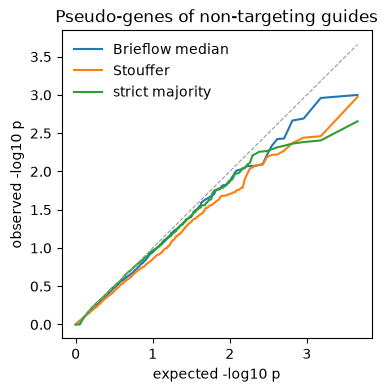

In [8]:
fig, ax = plt.subplots(figsize=(4, 4))
for name, (key, _) in METHODS.items():
    table = calib.uns["mantispy"][key]
    p = np.sort(table.loc[table["group"].str.startswith("PSEUDO"), "pvalue"].to_numpy())
    expected = (np.arange(p.size) + 0.5) / p.size
    ax.plot(-np.log10(expected), -np.log10(np.maximum(p, 1e-300)), label=name, lw=1.5)
top = -np.log10(0.5 / p.size)
ax.plot([0, top], [0, top], color="0.6", lw=0.8, ls="--")
ax.set(xlabel="expected -log10 p", ylabel="observed -log10 p", title="Pseudo-genes of non-targeting guides")
ax.legend(frameon=False)
plt.show()

No test calls too many pseudo-genes.
Every observed over expected ratio is at or below one, and in the QQ plot every curve stays on or under the diagonal, so all three tests are calibrated or conservative on the plate.
The q-values are taken over every real gene and feature, many of them called, so a calibrated test can still call a pseudo-gene pair now and then.
Brieflow's test, Stouffer and the strict majority call 4, 3 and 1 of the 2,280.

The tests differ in power.
Stouffer calls the most core essential genes, 84.3%, and ranks them highest, at an AUC of 0.845, against 0.825 for Brieflow's test and 0.809 for the strict majority.
The AUC intervals overlap, so one plate doesn't separate the tests firmly, but on this plate the strict majority gives up some power.

The olfactory-receptor genes give the rate of calls from cutting alone.
Every test calls about 1% of their gene and feature pairs and 7 to 9 of the 29 genes in at least one feature.
The strict majority calls fewer of the pairs than Stouffer, 0.8% against 1.2%, but one more of the genes, so the cutting controls don't separate the tests.
Non-essential genes are called more often, 40% to 43% of them in at least one of the 76 features, a count that includes cutting as well as real morphological effects of genes the cells don't need to grow.
To measure genes against cutting rather than against no cut, pass the cutting controls to `reference` as a boolean `obs` column, as [Hit callers on cells and on guide profiles](../tutorials/genetics/hit_calling_methods.ipynb) does for {func}`~mantispy.tl.hit_calling`.
Brieflow's test took more than a hundred times as long as the strict majority.

## One guide can carry a Stouffer call when guides differ

Guides of one gene often differ from each other by more than chance, and so do control guides.
The simulation below gives every guide, control or not, its own offset in each feature, drawn from a normal distribution with standard deviation `sd`, and gives no gene an effect.
Every call on the simulation is therefore false.
It has 200 control guides and 250 genes of four guides, each guide with 400 cells in 20 features, and a fixed seed.
A guide's median of 400 standard normal cells has a sampling error of about 0.06, so `sd = 0.3` gives guides offsets of about five times their sampling error.

In [9]:
def simulate(sd, seed=5):
    """Cells of 200 control guides and 250 genes of 4 guides, each guide offset by its own N(0, sd) per feature."""
    rng = np.random.default_rng(seed)
    units = [("nontargeting", f"nt{i}") for i in range(200)]
    units += [(f"PSEUDO{g}", f"ps{g}_{s}") for g in range(250) for s in range(4)]
    blocks = [rng.normal(size=(400, 20)) + rng.normal(scale=sd, size=20) for _ in units]
    frame = pd.DataFrame(np.concatenate(blocks), columns=[f"Cells_Intensity_F{i}" for i in range(20)])
    frame.insert(0, "Metadata_Plate", "simulated")
    frame.insert(1, "Metadata_Gene", np.repeat([u[0] for u in units], 400))
    frame.insert(2, "Metadata_sgRNA", np.repeat([u[1] for u in units], 400))
    frame.insert(3, "Metadata_Control_Type", np.where(frame["Metadata_Gene"] == "nontargeting", "negcon", "treatment"))
    return mt.io.from_dataframe(frame, resolution="object")


sim = simulate(0.3)
rows = {}
for name, (key, kwargs) in {**METHODS, "Fisher": ("fisher", {"method": "fisher"})}.items():
    mt.tl.bootstrap_features(sim, key_added=key, **kwargs)
    table = sim.uns["mantispy"][key]
    rows[name] = {
        "false calls at q < 0.05": int((table["qvalue"] < 0.05).sum()),
        "share at p < 0.05": round(float((table["pvalue"] < 0.05).mean()), 4),
    }
print(f"{sim.n_obs:,} cells, 250 genes of 4 guides with no effect, 20 features: 5,000 tests")
pd.DataFrame(rows).T

480,000 cells, 250 genes of 4 guides with no effect, 20 features: 5,000 tests


,false calls at q < 0.05,share at p < 0.05
Brieflow median,0.0,0.0476
Stouffer,4.0,0.0528
strict majority,0.0,0.0426
Fisher,36.0,0.0606


In [10]:
sim_guides = sim.uns["mantispy"]["order_guides"]  # every method writes the same guide table
false = sim.uns["mantispy"]["stouffer"].query("qvalue < 0.05")
majority = sim.uns["mantispy"]["order"].set_index(["group", "feature"])
for _, call in false.iterrows():
    rows = sim_guides[(sim_guides["group"] == call["group"]) & (sim_guides["feature"] == call["feature"])]
    print(
        f"{call['group']} {call['feature']}: Stouffer q = {call['qvalue']:.3g}, strict majority "
        f"q = {majority.loc[(call['group'], call['feature']), 'qvalue']:.3g}; guide p-values "
        + ", ".join(f"{p:.2g}" for p in rows["pvalue"])
    )

PSEUDO112 Cells_Intensity_F18: Stouffer q = 0.0072, strict majority q = 0.994; guide p-values 0.9, 0.53, 0.1, 2.9e-20
PSEUDO177 Cells_Intensity_F2: Stouffer q = 0.00348, strict majority q = 0.968; guide p-values 0.16, 0.00012, 0.34, 0.0002


PSEUDO216 Cells_Intensity_F19: Stouffer q = 0.0072, strict majority q = 0.994; guide p-values 0.01, 0.73, 9.2e-08, 0.41
PSEUDO76 Cells_Intensity_F18: Stouffer q = 0.00427, strict majority q = 0.794; guide p-values 0.085, 5.7e-08, 0.0018, 0.48


The strict majority and Brieflow's test make no false call, and Stouffer makes four.
Fisher, which calls a gene on any one strong guide, makes 36.
The share of p-values below 0.05 is near 0.05 for Stouffer, Brieflow's test and the strict majority, so Stouffer's false calls come from the far tail, not from a general excess.
Fisher's share, 0.061, is too high in general as well.
Each of Stouffer's false calls rests on one or two guides with a small p-value, as small as 2.9e-20 for one guide of `PSEUDO112`, whose other three guides don't move.

The cell below repeats the simulation with smaller offsets.
It counts the false calls of each rule, and how often the gene guides' own p-values fall below 0.001 and 1e-6, against how often they would if they were calibrated.

In [11]:
sweep = {}
for sd in (0.0, 0.1, 0.3):
    s = simulate(sd)
    row = {}
    for name, method in (("Stouffer", "stouffer"), ("strict majority", "order"), ("Fisher", "fisher")):
        mt.tl.bootstrap_features(s, key_added=method, method=method)
        row[f"{name}, false calls"] = int((s.uns["mantispy"][method]["qvalue"] < 0.05).sum())
    p = s.uns["mantispy"]["order_guides"]["pvalue"].to_numpy()
    for a in (1e-3, 1e-6):
        row[f"gene guides, observed / expected at p < {a:g}"] = round(float(np.mean(p < a) / a), 1)
    sweep[f"sd = {sd}"] = row
pd.DataFrame(sweep)

,sd = 0.0,sd = 0.1,sd = 0.3
"Stouffer, false calls",0.0,0.0,4.0
"strict majority, false calls",0.0,0.0,0.0
"Fisher, false calls",0.0,0.0,36.0
"gene guides, observed / expected at p < 0.001",0.0,0.7,3.9
"gene guides, observed / expected at p < 1e-06",0.0,0.0,1100.0


Without offsets, or with small ones, no rule makes a false call, and the guides' own p-values are calibrated or conservative.
At `sd = 0.3` the guide p-values are far too small in the tail, with 1,100 times as many below 1e-6 as a calibrated test would give.
The guide null treats the cells it resamples as independent draws, so a guide whose offset lies beyond those of all 200 control guides gets the chance that resampled cells reach its median, which can be 1e-20.
If guides were exchangeable, about one guide in 100 would lie beyond all the control guides, on one side or the other.
Stouffer and Fisher add such a guide's p-value to its siblings', while the strict majority reads the third smallest of four, so the one or two most extreme guides don't decide the call.
The strict majority therefore stays calibrated when the guides' own p-values fail in the far tail.

The spread between control guides on the plate is set against their sampling error below.
For each feature, the cell compares the spread of the 250 non-targeting guides' medians with the spread expected from sampling alone, estimated from two random halves of each guide's cells.

In [12]:
values = np.asarray(cells[control].layers["mad"], dtype=np.float64)
nt = obs.loc[control, "Metadata_sgRNA"].astype(str).to_numpy()
half = np.random.default_rng(2).integers(0, 2, size=nt.size)
frame = pd.DataFrame(values, columns=FEATURES)
medians = frame.groupby(nt).median()
halves = frame.groupby([nt, half]).median()
# a median of n cells has about twice the variance of one of 2n, so (half A - half B) / 2 has the variance of the full median
sampling = ((halves.xs(0, level=1) - halves.xs(1, level=1)) / 2).loc[medians.index]
between = np.sqrt(np.maximum(medians.var() - sampling.var(), 0))
ratio = between / sampling.std()
print(f"non-targeting guides' spread beyond sampling, over their sampling error, across the {len(FEATURES)} features:")
print(ratio.describe()[["min", "25%", "50%", "75%", "max"]].round(2).to_string())

non-targeting guides' spread beyond sampling, over their sampling error, across the 76 features:
min    0.00
25%    0.56
50%    0.81
75%    1.00
max    1.31


On this plate the non-targeting guides vary much less than in the simulation's `sd = 0.3`.
Their spread beyond sampling is at most 1.31 times their sampling error, with a median of 0.81, where `sd = 0.3` is about five times and `sd = 0.1` about 1.6 times.
The calibration above agrees, since no test overcalled the pseudo-genes.
Gene guides may vary more than control guides, through off-target cuts or uneven editing, and so may other screens' guides, which is where the strict majority's protection counts.

## What guide_qc flags

{func}`~mantispy.pp.guide_qc` reads the latest {func}`~mantispy.tl.bootstrap_features` result and flags each gene guide in three ways.

- A guide is inactive when its median profile, over all features, is no further from the non-targeting guides' than they are from each other, a {func}`~mantispy.tl.guide_activity` p-value of at least 0.05.
  The flag applies only while at least half of its sibling guides are active, so a gene that does nothing doesn't get all its guides flagged.
- A guide is outlying when, in a feature where it is its gene's most extreme guide, it differs from the cell-weighted mean of its siblings by more than its standard error allows, after a Bonferroni correction over those features.
  Genes of fewer than three guides aren't tested.
- A guide is thin when it has fewer than 10 cells.

The cell runs it on the plate and on the pseudo-gene object.
A pseudo-gene guide is a non-targeting guide, so an outlier flag on one is a false flag, while an inactive flag fires only when its siblings look active by chance.

In [13]:
mt.pp.guide_qc(cells)
flags = cells.uns["mantispy"]["guide_qc"]
FLAGS = ["qc_guide_inactive_fail", "qc_guide_outlier_fail", "qc_guide_cells_fail", "qc_guide_fail"]

mt.pp.guide_qc(calib, key="order")
calib_flags = calib.uns["mantispy"]["guide_qc"]
pseudo_flags = calib_flags[calib_flags["group"].str.startswith("PSEUDO")]
pd.DataFrame(
    {
        f"{len(flags):,} gene guides": flags[FLAGS].sum(),
        "share": flags[FLAGS].mean().round(3),
        f"{len(pseudo_flags)} pseudo-gene guides": pseudo_flags[FLAGS].sum(),
        "share ": pseudo_flags[FLAGS].mean().round(3),
    }
)

,"20,185 gene guides",share,120 pseudo-gene guides,share
qc_guide_inactive_fail,1253,0.062,4,0.033
qc_guide_outlier_fail,2550,0.126,7,0.058
qc_guide_cells_fail,61,0.003,0,0.000
qc_guide_fail,3550,0.176,11,0.092


On the plate, 3,550 of the 20,185 gene guides (17.6%) fail at least one flag, most of them as outlying (12.6%).
Of the pseudo-gene guides, 7 of 120 (5.8%) are flagged as outlying, an estimate of the rate at which the outlier flag fires on guides with no effect.
Taken at face value, about half of the plate's outlier flags could be chance, though 7 of 120 leaves that share uncertain.
Read a flag as a reason to look at a guide, not as proof that it failed.

The cell below prints SNRPA1's flags and its row of the per-gene summary for the feature above.

In [14]:
print(flags.loc[flags["group"] == "SNRPA1", ["replicate", "n_cells", "activity_pvalue", *FLAGS]].to_string(index=False))
summary = cells.uns["mantispy"]["guide_qc_summary"]
summary[(summary["group"] == "SNRPA1") & (summary["feature"] == "cell_GH2AX_std_edge")]

  replicate  n_cells  activity_pvalue  qc_guide_inactive_fail  qc_guide_outlier_fail  qc_guide_cells_fail  qc_guide_fail
AAATCCAGTAC       86         0.003984                   False                  False                False          False
GACGGCGGAGC       27         0.003984                   False                  False                False          False
GGCGGCGCAGT       54         0.003984                   False                   True                False           True
TCAAATCGCTG      148         0.003984                   False                  False                False          False


,group,feature,n_guides,n_usable,n_agree,n_significant,cochran_q,cochran_pvalue,i2,majority,single_guide
307016,SNRPA1,cell_GH2AX_std_edge,4,3,4,3,7.471986,0.058283,0.5985,True,False


`GGCGGCGCAGT`, the SNRPA1 guide that moved furthest, is flagged as outlying, so `n_usable` is three.
The summary has one row per gene and feature, with these columns.

- `n_guides` counts the guides with a p-value, and `n_usable` those of them with no flag.
- `n_agree` counts the guides that move the gene's way, and `n_significant` those of them below the one-sided level at which a strict majority gives the gene p < 0.05.
- `majority` says whether `n_significant` is a strict majority, which is whether the strict majority gives the gene p < 0.05.
- `cochran_q`, `cochran_pvalue` and `i2` give Cochran's Q test of whether the guides' effects differ by more than chance, and I², the share of their spread beyond chance.
  SNRPA1's I² of 0.60 hints that its guides differ, though not significantly at a Cochran p-value of 0.058, and Stouffer's sum ignores such differences.
- `single_guide` marks a called gene of two or more guides with only one significant guide, which can't happen under the default.

## Calls the majority misses because of inactive guides

A guide that doesn't cut votes against its gene under the strict majority.
With two inactive guides of four, the two active guides can't make a majority alone, so the gene is called only in a feature where an inactive guide moves too.
The cell below counts the genes with two or more inactive guides and compares their calls, on at least one feature, under both rules.

In [15]:
inactive = flags.groupby("group")["qc_guide_inactive_fail"].sum()
two_dead = inactive[inactive >= 2].index
called = {
    name: cells.uns["mantispy"][key].groupby("group")["qvalue"].min().lt(0.05)[two_dead]
    for name, key in (("strict majority", "bootstrap"), ("Stouffer", "stouffer"))
}
print(f"{len(two_dead)} genes have two or more inactive guides; {len(set(two_dead) & ESSENTIAL)} are core essential")
print(
    pd.crosstab(called["strict majority"], called["Stouffer"]).rename_axis(index="strict majority", columns="Stouffer")
)
majority_called = called["strict majority"].index[called["strict majority"]]
missed = sorted((set(two_dead) & ESSENTIAL) - set(majority_called))
print(f"core essential genes with two inactive guides and no call under the strict majority: {', '.join(missed)}")
print(f"of those, called under Stouffer: {', '.join(g for g in missed if called['Stouffer'][g])}")

475 genes have two or more inactive guides; 98 are core essential
Stouffer         False  True 
strict majority              
False               68     31
True                21    355
core essential genes with two inactive guides and no call under the strict majority: ALG2, CENPC, CMTR1, COX11, DDX20, DLST, DNAJC9, EXOSC6, GPN3, LTO1, MRPL57, MRPS24, MTG2, NKAP, RPP21, SPC25, TELO2, TPX2, TTI2, VPS25
of those, called under Stouffer: ALG2, CENPC, DDX20, DLST, EXOSC6, LTO1, MRPL57, MTG2, TPX2, VPS25


SF3B2, another core essential spliceosome gene with two inactive guides, shows how the majority misses a gene in one feature.
The cell prints its guides' flags and how many features each rule calls it in, then works through the gamma-H2AX intensity at the nuclear edge.

In [16]:
print(flags.loc[flags["group"] == "SF3B2", ["replicate", "n_cells", "activity_pvalue", *FLAGS]].to_string(index=False))
for name, key in (("strict majority", "bootstrap"), ("Stouffer", "stouffer")):
    table = cells.uns["mantispy"][key]
    print(f"{name} calls SF3B2 in {int((table.loc[table['group'] == 'SF3B2', 'qvalue'] < 0.05).sum())} features")
worked("SF3B2", "nucleus_GH2AX_mean_edge")

  replicate  n_cells  activity_pvalue  qc_guide_inactive_fail  qc_guide_outlier_fail  qc_guide_cells_fail  qc_guide_fail
CCGAATGAACC      102         0.007968                   False                  False                False          False
CGCCGCCAACA      104         0.003984                   False                   True                False           True
CTGCATGGCAA      113         0.195219                    True                  False                False           True
GAGAATTCATC      160         0.143426                    True                   True                False           True
strict majority calls SF3B2 in 7 features
Stouffer calls SF3B2 in 29 features
SF3B2, nucleus_GH2AX_mean_edge: 4 guides, so a strict majority is 3
guides at one-sided p < 0.05: 2 up, 0 down
strict majority recomputed here: p = 0.00649


strict majority from bootstrap_features: p = 0.00649, q = 0.0916
Stouffer from bootstrap_features: p = 7.98e-10, q = 7.52e-08


,replicate,n_cells,effect,pvalue,p_up,p_down
1170866,CCGAATGAACC,102,0.6773,0.0011,0.0005,0.9995
1170942,CGCCGCCAACA,104,2.0536,0.0000,0.0000,1.0000
1171018,CTGCATGGCAA,113,0.2044,0.2150,0.1075,0.8925
1171094,GAGAATTCATC,160,0.1847,0.1912,0.0956,0.9044


Of the 475 genes with two inactive guides, the strict majority calls 376 in at least one feature and Stouffer calls 386.
Both call 355, the majority alone 21, and Stouffer alone 31.
The 98 core essential genes among them include 20 that the majority calls in no feature, and Stouffer calls 10 of the 20.

SF3B2's guides `CTGCATGGCAA` and `GAGAATTCATC` are flagged inactive, and in the gamma-H2AX intensity at the nuclear edge they move up only a little, at one-sided p-values of 0.11 and 0.096.
The two other guides move up strongly, but the third smallest one-sided p-value is 0.096.
The majority's p-value is therefore 0.0065, q = 0.09, so SF3B2 isn't called in the feature, while Stouffer adds the four z-scores and calls it at q = 7.5e-08.
Over all features, the majority calls SF3B2 in 7 and Stouffer in 29.

An inactive guide of an essential gene needn't be a bad reagent.
In an optical pooled screen, cells that lost an essential gene can die before imaging, so a guide's imaged cells can be mostly unedited ones that look like controls.
Either way, a gene missed with two inactive guides is a lead to check, not evidence that the gene does nothing.

`exclude="qc_guide_fail"` on {func}`~mantispy.tl.bootstrap_features` tests again without the flagged guides, which lowers `k` and with it the number of guides a gene needs.
For SF3B2 it would leave one guide of four, since `CGCCGCCAACA` is flagged as outlying too.
The flags come from the same cells and features as the test, though.
Dropping guides because they disagree with their siblings selects on the data, and the guides left agree more than chance would make them, so the p-values come out too small.
Exclude a guide only on evidence the test didn't use, e.g. inactivity measured on a separate readout or on half of the cells, or a thin guide.

## Which gene test to use

Use the default, `method="order"`, for a real screen.
It calls a gene on what most of its guides share, so one off-target or merely extreme guide can't carry a gene, and it stays calibrated when the guides' own p-values are too small in the far tail, as in the simulation.
It costs some power, and on this plate it called fewer core essential genes than Stouffer and ranked them lower.
{func}`~mantispy.pp.guide_qc` shows where some of that power goes, to genes with inactive guides, e.g. the 20 core essential genes with two inactive guides that the majority missed.
Stouffer suits a screen whose guides behave alike, and Cochran's Q and I² in the summary of {func}`~mantispy.pp.guide_qc` show per gene and feature how much they differ.
Brieflow's test was as calibrated as the majority here and made no false call in the simulation, but it took more than a hundred times as long.

| `method` | calls a gene when | choose it |
| --- | --- | --- |
| `"order"` (default) | a strict majority of its guides, `k // 2 + 1` of `k`, move the same way | for real screens |
| `"stouffer"` | the sum of its guides' z-scores, weighted by the root of their cells, is large | for more power when a gene's guides are known to behave alike |
| `"fisher"` | any one guide is strongly significant | to find genes with a single potent guide, accepting that an off-target guide can carry a gene |
| `"median"` | the median of its guides' medians is far from the null of that median | to compare with Brieflow |

`median="midpoint"` takes the median of an even count as the mean of the two middle values, as Brieflow and {func}`numpy.median` do.
With `method="median"` it is Brieflow's gene test, and [Coming from Brieflow](../tutorials/genetics/coming_from_brieflow.ipynb) compares its p-values with the ones Brieflow published.
Use it only to reproduce Brieflow's numbers, since it doesn't scale to large feature sets or the largest screens.